# 6. Siapa yang untung kalau harga bahan mie ayam naik? 

Di notebook 2-5 aku hitung biaya bahan semangkuk mie ayam. Sekarang pertanyaannya dibalik: **kalau biaya bahan naik, perusahaan mana yang kelihatannya ikut untung?**

Aku pakai harga saham 5 perusahaan pangan di bursa (IDX) sebagai "petunjuk":

| Ticker | Perusahaan | Kenapa dipilih |
|---|---|---|
| CPIN | Charoen Pokphand | ayam (±70% biaya bahan) |
| JPFA | Japfa Comfeed | ayam |
| INDF | Indofood | mie instan (pembanding) |
| ICBP | Indofood CBP | mie instan (pembanding) |
| AALI | Astra Agro Lestari | sawit, bahan baku minyak goreng |

**Catatan jujur dari awal:** ini bukan analisis investasi. Harga saham dipengaruhi banyak hal selain harga pangan, dan datanya cuma ±69 bulan. Nanti hasilnya kubaca sebagai *korelasi*, bukan sebab-akibat.

Bagian 1: siapkan data (biaya per porsi + harga saham, digabung per bulan). Bagian 2: cek apakah gerakannya berhubungan.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf   # di Kaggle: Settings > Internet harus ON

## Langkah 1: bangun ulang biaya per porsi (sama seperti notebook 5b)
Resep: ayam 60 g, bawang merah 10 g, bawang putih 5 g, minyak 20 ml. Terigu tidak dihitung (alasannya ada di 5b).

In [22]:
DATA ='/kaggle/input/datasets/samuelgeraldo/bedah-mie-ayam-pakai-data-bukan-sumpit/harga_pangan_bersih.csv'
df = pd.read_csv(DATA)
wide = df.pivot(index='bulan', columns='komoditas', values='harga_rp')
wide.index = pd.to_datetime(wide.index)
wide = wide.interpolate(limit_direction='both')
wide = wide[wide.index < '2026-10-01']   # Okt 2026 belum lengkap

minyak = wide[['Minyak Goreng Kemasan Bermerk 1', 'Minyak Goreng Kemasan Bermerk 2']].mean(axis=1)
biaya = pd.DataFrame({
    'ayam': wide['Daging Ayam Ras Segar']*60/1000,
    'bawang_merah': wide['Bawang Merah Ukuran Sedang']*10/1000,
    'bawang_putih': wide['Bawang Putih Ukuran Sedang']*5/1000,
    'minyak': minyak*20/1000})
biaya['total'] = biaya.sum(axis=1)
print(biaya['total'].iloc[[0, -1]].round(0))   # harus 2763 (Jan 2021) dan 3613 (Sep 2026)
print(len(biaya), 'bulan')

bulan
2021-01-01    2763.0
2026-09-01    3613.0
Name: total, dtype: float64
69 bulan


## Langkah 2: ambil harga saham bulanan
`auto_adjust=True` artinya harga sudah disesuaikan dengan dividen dan stock split, jadi perubahan harganya tidak "palsu".

In [23]:
tickers = ['CPIN.JK', 'JPFA.JK', 'INDF.JK', 'ICBP.JK', 'AALI.JK']
saham = yf.download(tickers, start='2021-01-01', end='2026-10-01',
                    interval='1mo', auto_adjust=True, progress=False)['Close']
saham.columns = [t.replace('.JK', '') for t in saham.columns]
saham.index = pd.to_datetime(saham.index).to_period('M').to_timestamp()   # samakan ke tanggal 1 tiap bulan
print(saham.shape, '| nilai kosong:', int(saham.isna().sum().sum()))
saham.head()

(69, 5) | nilai kosong: 0


,AALI,CPIN,ICBP,INDF,JPFA
Date,,,,,
2021-01-01,8532.780273,5047.535156,7841.272949,4750.478027,1067.349243
2021-02-01,8590.045898,5398.668945,7388.892578,4750.478027,1204.692139
2021-03-01,7654.685059,6144.826172,7927.439941,5182.339844,1506.846069
2021-04-01,7237.055664,6188.716797,7496.601074,5123.449219,1687.058716
2021-05-01,6849.008301,5925.367676,7065.762207,4986.039062,1591.112305


## Langkah 3: ubah semuanya jadi "perubahan % dari bulan sebelumnya"
Harga saham (ribuan rupiah) dan biaya mie (ribuan rupiah juga, tapi skalanya beda) tidak bisa dibandingkan langsung. Yang dibandingkan adalah **persen perubahannya**, sama seperti di notebook 5.

In [24]:
gabung = pd.concat([biaya['total'].rename('biaya_mie'), saham], axis=1)
print('bulan di biaya:', len(biaya), '| bulan di saham:', len(saham), '| bulan gabungan:', len(gabung.dropna()))

perubahan = gabung.pct_change().dropna() * 100
perubahan.round(2).head(8)

bulan di biaya: 69 | bulan di saham: 69 | bulan gabungan: 69


,biaya_mie,AALI,CPIN,ICBP,INDF,JPFA
2021-02-01,0.00,0.67,6.96,-5.77,0.00,12.87
2021-03-01,2.96,-10.89,13.82,7.29,9.09,25.08
2021-04-01,1.20,-5.46,0.71,-5.43,-1.14,11.96
2021-05-01,2.28,-5.36,-4.26,-5.75,-2.68,-5.69
2021-06-01,18.07,-13.88,-7.41,-0.61,-2.76,-13.07
2021-07-01,-15.51,4.61,-2.00,-0.31,-1.62,-9.83
2021-08-01,-6.12,6.29,6.38,3.69,1.65,16.03
2021-09-01,1.99,15.68,0.39,1.67,7.45,9.12


## Langkah 4: lihat sekilas
Semua dinormalkan ke 100 di Jan 2021 supaya bisa ditaruh di satu grafik.

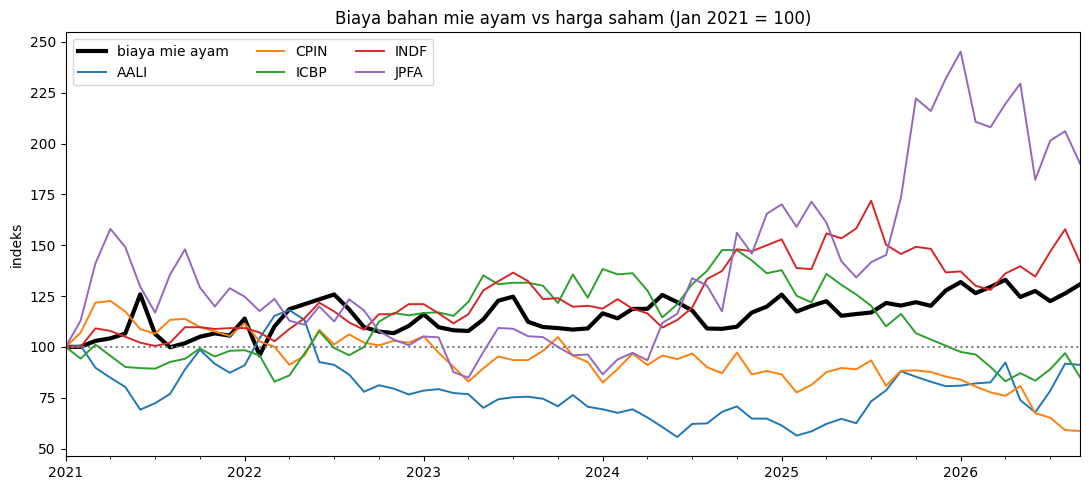

CPIN        -41.4
ICBP        -14.9
AALI         -8.8
biaya_mie    30.8
INDF         41.6
JPFA         90.2
Name: 2026-09-01 00:00:00, dtype: float64


In [25]:
indeks = gabung / gabung.iloc[0] * 100
fig, ax = plt.subplots(figsize=(11, 5))
indeks['biaya_mie'].plot(ax=ax, color='black', lw=3, label='biaya mie ayam')
indeks.drop(columns='biaya_mie').plot(ax=ax, lw=1.4)
ax.axhline(100, color='grey', ls=':')
ax.set_title('Biaya bahan mie ayam vs harga saham (Jan 2021 = 100)')
ax.set_ylabel('indeks'); ax.set_xlabel('')
ax.legend(ncol=3)
plt.tight_layout(); plt.show()

print((indeks.iloc[-1] - 100).round(1).sort_values())   # naik/turun berapa % sejak Jan 2021

In [26]:
gabung.to_csv('biaya_vs_saham_bulanan.csv')   # disimpan untuk bagian 2

---
# Bagian 2: apakah biaya mie dan saham bergerak bareng?

**Metodenya: korelasi (Pearson) antara perubahan % bulanan.** Angkanya dari -1 sampai +1:
- mendekati **+1**: kalau biaya mie naik bulan itu, saham cenderung ikut naik
- mendekati **-1**: biaya naik, saham cenderung turun
- mendekati **0**: tidak ada pola yang jelas

Kenapa pakai *perubahan %*, bukan harganya langsung? Dua hal yang sama-sama naik pelan-pelan selama 5 tahun akan terlihat berkorelasi tinggi walau tidak berhubungan sama sekali (korelasi palsu). Perubahan bulanan membuang efek tren itu.

In [27]:
from scipy import stats

hasil = []
for t in ['CPIN', 'JPFA', 'INDF', 'ICBP', 'AALI']:
    r, p = stats.pearsonr(perubahan['biaya_mie'], perubahan[t])
    hasil.append({'saham': t, 'korelasi': round(r, 2), 'p_value': round(p, 3), 'n_bulan': len(perubahan)})
tabel = pd.DataFrame(hasil).set_index('saham')
tabel['signifikan (p<0.05)'] = tabel['p_value'] < 0.05
tabel

,korelasi,p_value,n_bulan,signifikan (p<0.05)
saham,,,,
CPIN,-0.00,0.999,68,False
JPFA,0.08,0.533,68,False
INDF,0.01,0.923,68,False
ICBP,-0.13,0.307,68,False
AALI,-0.09,0.443,68,False


**Cara baca `p_value`:** peluang melihat korelasi sebesar itu *kalau sebenarnya tidak ada hubungan*. Makin kecil makin meyakinkan; batas umum 0.05. Dengan cuma 68 bulan, korelasi harus lumayan besar (kira-kira lebih dari 0.24) baru lolos batas itu.

## Apakah saham bergerak lebih dulu atau belakangan?
Bisa jadi pasar bereaksi dulu sebelum harga ayam di pasar berubah, atau sebaliknya. Kita geser return saham beberapa bulan dan hitung korelasinya lagi:
- `lag -1`: return saham **sebulan sebelum** perubahan biaya
- `lag 0`: bulan yang sama
- `lag +1`: return saham **sebulan sesudah** perubahan biaya

In [28]:
baris = {}
for t in ['CPIN', 'JPFA', 'INDF', 'ICBP', 'AALI']:
    baris[t] = {f'lag {k:+d}': round(perubahan['biaya_mie'].corr(perubahan[t].shift(-k)), 2) for k in [-2, -1, 0, 1, 2]}
lag = pd.DataFrame(baris).T
lag

,lag -2,lag -1,lag +0,lag +1,lag +2
CPIN,-0.09,-0.00,-0.00,-0.04,0.11
JPFA,-0.09,0.13,0.08,-0.07,0.09
INDF,0.03,0.06,0.01,0.02,-0.32
ICBP,0.09,-0.08,-0.13,0.01,-0.06
AALI,0.21,0.07,-0.09,-0.11,-0.25


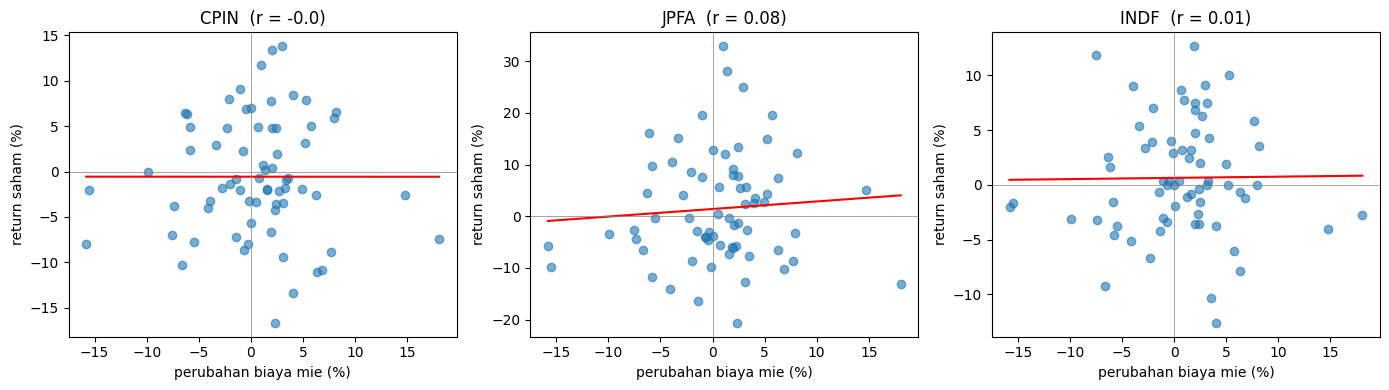

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, t in zip(axes, ['CPIN', 'JPFA', 'INDF']):
    ax.scatter(perubahan['biaya_mie'], perubahan[t], alpha=0.6)
    m, b = np.polyfit(perubahan['biaya_mie'], perubahan[t], 1)
    xs = np.linspace(perubahan['biaya_mie'].min(), perubahan['biaya_mie'].max(), 50)
    ax.plot(xs, m*xs + b, color='red')
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(f"{t}  (r = {tabel.loc[t, 'korelasi']})")
    ax.set_xlabel('perubahan biaya mie (%)'); ax.set_ylabel('return saham (%)')
plt.tight_layout(); plt.show()

## Kesimpulan
Perubahan bulanan biaya mie ayam tidak berkorelasi dengan return CPIN, JPFA, INDF, ICBP, maupun AALI (semua |r| < 0.15, tidak ada yang signifikan). Saham ayam bisa naik atau turun jauh (JPFA +90%, CPIN -41% sejak Jan 2021) tanpa mengikuti harga ayam eceran, karena harga saham mencerminkan laba seluruh bisnis dan sentimen pasar. Jawaban jujur untuk "siapa yang untung?": dari data ini tidak bisa ditunjuk.